# Kepler Exoplanet Classification: v2 (rigorous evaluation)

**What changed vs. v1**
1. No 100k upsampling. Models train on the real rows only, and imbalance is handled with class weights.
2. Imputer + scaler live **inside** the Pipeline, so CV is leak-free and the saved model accepts raw rows with NaN.
3. Repeated stratified CV (mean ± std) instead of one split. Metrics: F1, PR-AUC, MCC, ROC-AUC.
4. Feature ablation: does the model rely on `_err` (uncertainty) or non-physical columns (ra, dec, kepmag, ...)?
5. Every model gets the same tuning budget, including logistic regression, plus a paper-style MLP baseline.
6. The model is selected by CV score, and the test set is touched once, with bootstrap 95% CIs.
7. Permutation importance + SHAP, and a ranking of the CANDIDATE rows.

In [1]:
# 0. Setup
import importlib, subprocess, sys, warnings
for pkg in ["shap", "lightgbm", "xgboost"]:
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = "/content/drive/MyDrive/cumulative.csv"   # change if needed
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    DATA_PATH = "cumulative.csv"                       # running locally

df = pd.read_csv(DATA_PATH)
print("Initial shape:", df.shape)
print(df["koi_disposition"].value_counts())

Mounted at /content/drive
Initial shape: (9564, 50)
koi_disposition
FALSE POSITIVE    5023
CONFIRMED         2293
CANDIDATE         2248
Name: count, dtype: int64


In [3]:
# 1. Build X, y  (CONFIRMED = 1, FALSE POSITIVE = 0). CANDIDATE rows are kept aside for later.
LEAK = ["kepid", "kepoi_name", "kepler_name", "koi_pdisposition", "rowid",
        "koi_score", "koi_fpflag_nt", "koi_fpflag_ss", "koi_fpflag_co", "koi_fpflag_ec"]

lab = df[df["koi_disposition"].isin(["CONFIRMED", "FALSE POSITIVE"])].copy()
y = (lab["koi_disposition"] == "CONFIRMED").astype(int).reset_index(drop=True)

X = lab.drop(columns=[c for c in LEAK + ["koi_disposition"] if c in lab.columns])
X = X.select_dtypes(include=[np.number])
X = X.loc[:, X.isnull().mean() <= 0.40].reset_index(drop=True)   # drop columns with >40% missing

ALL = list(X.columns)
ERR = [c for c in ALL if c.endswith(("_err1", "_err2"))]
NONPHYS = [c for c in ["ra", "dec", "koi_kepmag", "koi_tce_plnt_num", "koi_time0bk"] if c in ALL]

FEATURE_SETS = {
    "all": ALL,
    "no_err": [c for c in ALL if c not in ERR],
    "no_nonphys": [c for c in ALL if c not in NONPHYS],
    "no_err_no_nonphys": [c for c in ALL if c not in ERR + NONPHYS],
}
print({k: len(v) for k, v in FEATURE_SETS.items()})
print("Rows:", len(X), "| positive rate:", round(y.mean(), 3))

{'all': 36, 'no_err': 16, 'no_nonphys': 31, 'no_err_no_nonphys': 11}
Rows: 7316 | positive rate: 0.313


In [9]:
# 2. Hold-out split (same seed as v1). Touched ONCE, at the very end.
from sklearn.model_selection import train_test_split
MODEL_NAMES = ["LogReg", "XGBoost", "LightGBM"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
pos_w = (y_train == 0).sum() / (y_train == 1).sum()   # for XGBoost scale_pos_weight
print(X_train.shape, X_test.shape, "| scale_pos_weight =", round(pos_w, 2))

(5852, 36) (1464, 36) | scale_pos_weight = 2.19


In [5]:
# 3. Models as full pipelines: impute (median) -> scale -> classifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

MODEL_NAMES = ["LogReg", "RandomForest", "XGBoost", "LightGBM", "MLP (paper-style)"]

def make_pipe(name, weighted=True, seed=42):
    cw = "balanced" if weighted else None
    if name == "LogReg":
        clf = LogisticRegression(max_iter=2000, class_weight=cw, random_state=seed)
    elif name == "RandomForest":
        clf = RandomForestClassifier(n_estimators=300, class_weight=cw, random_state=seed, n_jobs=1)
    elif name == "XGBoost":
        clf = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.05, subsample=0.8,
                            scale_pos_weight=pos_w if weighted else 1.0,
                            eval_metric="logloss", random_state=seed, n_jobs=1)
    elif name == "LightGBM":
        clf = LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, subsample=0.8,
                             subsample_freq=1, class_weight=cw, random_state=seed, verbose=-1, n_jobs=1)
    elif name == "MLP (paper-style)":
        # Check the paper's exact architecture / hyperparameters and edit here if they differ.
        clf = MLPClassifier(hidden_layer_sizes=(300, 200, 200, 100, 100), early_stopping=True,
                            max_iter=300, random_state=seed)
    else:
        raise ValueError(name)
    return Pipeline([("imputer", SimpleImputer(strategy="median")),
                     ("scaler", StandardScaler()),
                     ("clf", clf)])

In [6]:
# 4. Benchmark: repeated stratified CV on the TRAIN split, all models x all feature sets
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, matthews_corrcoef

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=42)
scoring = {"f1": "f1", "pr_auc": "average_precision", "roc_auc": "roc_auc",
           "mcc": make_scorer(matthews_corrcoef), "recall": "recall", "precision": "precision"}

rows = []
for fs_name, cols in FEATURE_SETS.items():
    for m in MODEL_NAMES:
        res = cross_validate(make_pipe(m), X_train[cols], y_train, cv=cv, scoring=scoring, n_jobs=-1)
        row = {"features": fs_name, "model": m}
        for k in scoring:
            row[k + "_mean"] = res["test_" + k].mean()
            row[k + "_std"] = res["test_" + k].std()
        rows.append(row)
        print(f"done: {fs_name:18s} {m}")

bench = pd.DataFrame(rows)

def fmt(metric):
    t = bench.copy()
    t[metric] = t[metric + "_mean"].map("{:.3f}".format) + " ± " + t[metric + "_std"].map("{:.3f}".format)
    return t.pivot(index="model", columns="features", values=metric)[list(FEATURE_SETS)]

for metric in ["f1", "pr_auc", "mcc"]:
    print(f"\n=== {metric.upper()} (mean ± std over 10 folds) ===")
    print(fmt(metric).to_string())

done: all                LogReg
done: all                RandomForest
done: all                XGBoost
done: all                LightGBM
done: all                MLP (paper-style)
done: no_err             LogReg
done: no_err             RandomForest
done: no_err             XGBoost
done: no_err             LightGBM
done: no_err             MLP (paper-style)
done: no_nonphys         LogReg
done: no_nonphys         RandomForest
done: no_nonphys         XGBoost
done: no_nonphys         LightGBM
done: no_nonphys         MLP (paper-style)
done: no_err_no_nonphys  LogReg
done: no_err_no_nonphys  RandomForest
done: no_err_no_nonphys  XGBoost
done: no_err_no_nonphys  LightGBM
done: no_err_no_nonphys  MLP (paper-style)

=== F1 (mean ± std over 10 folds) ===
features                     all         no_err     no_nonphys no_err_no_nonphys
model                                                                           
LightGBM           0.921 ± 0.009  0.901 ± 0.009  0.914 ± 0.010     0.895 ± 0.01

**How to read the ablation:** compare the `all` column with `no_err` and `no_err_no_nonphys`.
- Scores barely drop, so the model is learning real physics (period, depth, SNR, planet radius, ...).
- Scores drop a lot, so the model leans on uncertainty or identifier-like columns, which is a shortcut worth reporting.

In [11]:
# 5. Choose a feature set (edit after reading the ablation table) and tune all models with the SAME budget
from scipy.stats import randint, uniform, loguniform
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

CHOSEN_SET = "no_err_no_nonphys"      # <- physically defensible default; change if you prefer
cols = FEATURE_SETS[CHOSEN_SET]
N_ITER = 5                            # identical for every model

SEARCH = {
    "LogReg": {"clf__C": loguniform(1e-3, 1e2)},
    "RandomForest": {"clf__n_estimators": randint(200, 600), "clf__max_depth": randint(6, 25),
                     "clf__min_samples_leaf": randint(1, 8), "clf__max_features": ["sqrt", "log2", 0.5]},
    "XGBoost": {"clf__n_estimators": randint(150, 600), "clf__max_depth": randint(3, 9),
                "clf__learning_rate": loguniform(0.02, 0.2), "clf__subsample": uniform(0.6, 0.4),
                "clf__colsample_bytree": uniform(0.6, 0.4), "clf__min_child_weight": randint(1, 8)},
    "LightGBM": {"clf__n_estimators": randint(150, 600), "clf__num_leaves": randint(15, 80),
                 "clf__learning_rate": loguniform(0.02, 0.2), "clf__subsample": uniform(0.6, 0.4),
                 "clf__colsample_bytree": uniform(0.6, 0.4), "clf__min_child_samples": randint(10, 50)},
    "MLP (paper-style)": {"clf__alpha": loguniform(1e-5, 1e-2), "clf__learning_rate_init": loguniform(1e-4, 1e-2)},
}

tuned = {}
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for m in MODEL_NAMES:
    s = RandomizedSearchCV(make_pipe(m), SEARCH[m], n_iter=N_ITER, cv=inner_cv,
                           scoring="average_precision", random_state=42, n_jobs=-1, refit=True)
    s.fit(X_train[cols], y_train)
    tuned[m] = s
    print(f"{m:20s} best CV PR-AUC = {s.best_score_:.4f}")

best_name = max(tuned, key=lambda k: tuned[k].best_score_)   # chosen by CV, NOT by test score
best = tuned[best_name].best_estimator_
print("\nSelected model (by CV):", best_name)

LogReg               best CV PR-AUC = 0.7355
XGBoost              best CV PR-AUC = 0.9501
LightGBM             best CV PR-AUC = 0.9518

Selected model (by CV): LightGBM


In [12]:
# 6. Final hold-out evaluation (once) with bootstrap 95% confidence intervals
from sklearn.metrics import (f1_score, matthews_corrcoef, average_precision_score, roc_auc_score,
                             recall_score, precision_score, confusion_matrix)

def all_metrics(yt, yp, ypr):
    return {"F1": f1_score(yt, yp), "PR-AUC": average_precision_score(yt, ypr),
            "MCC": matthews_corrcoef(yt, yp), "ROC-AUC": roc_auc_score(yt, ypr),
            "Recall": recall_score(yt, yp), "Precision": precision_score(yt, yp)}

def boot_ci(yt, yp, ypr, n=1000, seed=42):
    rng = np.random.default_rng(seed)
    yt, yp, ypr = map(np.asarray, (yt, yp, ypr))
    out = {k: [] for k in all_metrics(yt, yp, ypr)}
    for _ in range(n):
        i = rng.integers(0, len(yt), len(yt))
        if len(np.unique(yt[i])) < 2:
            continue
        for k, v in all_metrics(yt[i], yp[i], ypr[i]).items():
            out[k].append(v)
    return {k: (np.percentile(v, 2.5), np.percentile(v, 97.5)) for k, v in out.items()}

report = []
for m in MODEL_NAMES:
    est = tuned[m].best_estimator_
    yp, ypr = est.predict(X_test[cols]), est.predict_proba(X_test[cols])[:, 1]
    pt, ci = all_metrics(y_test, yp, ypr), boot_ci(y_test, yp, ypr)
    report.append({"model": m, **{k: f"{pt[k]:.3f} [{ci[k][0]:.3f}, {ci[k][1]:.3f}]" for k in pt}})
print(pd.DataFrame(report).set_index("model").to_string())

est = best
print("\nConfusion matrix for", best_name, "(rows = true 0/1, cols = predicted 0/1):")
print(confusion_matrix(y_test, est.predict(X_test[cols])))

                            F1                PR-AUC                   MCC               ROC-AUC                Recall             Precision
model                                                                                                                                       
LogReg    0.744 [0.713, 0.773]  0.732 [0.684, 0.779]  0.619 [0.581, 0.656]  0.894 [0.877, 0.910]  0.898 [0.870, 0.922]  0.636 [0.598, 0.673]
XGBoost   0.899 [0.876, 0.919]  0.959 [0.944, 0.971]  0.852 [0.820, 0.880]  0.980 [0.973, 0.986]  0.924 [0.900, 0.947]  0.876 [0.843, 0.905]
LightGBM  0.893 [0.869, 0.914]  0.958 [0.941, 0.971]  0.842 [0.810, 0.872]  0.980 [0.973, 0.986]  0.915 [0.891, 0.941]  0.871 [0.838, 0.900]

Confusion matrix for LightGBM (rows = true 0/1, cols = predicted 0/1):
[[943  62]
 [ 39 420]]


Threshold 0.901 gives precision 0.950 at recall 0.749


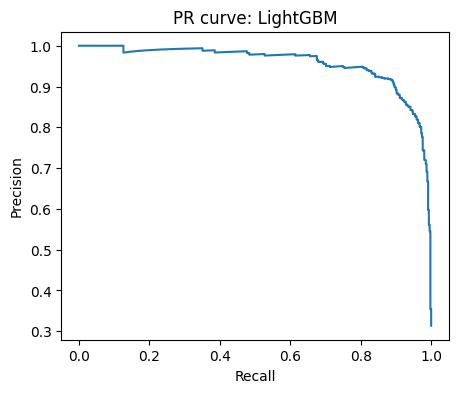

In [13]:
# 7. High-purity operating point (useful when false alarms are costly)
from sklearn.metrics import precision_recall_curve

ypr = best.predict_proba(X_test[cols])[:, 1]
prec, rec, thr = precision_recall_curve(y_test, ypr)
ok = np.where(prec[:-1] >= 0.95)[0]
if len(ok):
    i = ok[0]
    print(f"Threshold {thr[i]:.3f} gives precision {prec[i]:.3f} at recall {rec[i]:.3f}")
else:
    print("No threshold reaches precision 0.95 on this test set.")

plt.figure(figsize=(5, 4))
plt.plot(rec, prec)
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title(f"PR curve: {best_name}")
plt.show()

Top permutation importances (drop in PR-AUC):
koi_model_snr    0.1408
koi_prad         0.0988
koi_duration     0.0584
koi_period       0.0537
koi_impact       0.0467
koi_depth        0.0275
koi_srad         0.0177
koi_steff        0.0171
koi_insol        0.0148
koi_teq          0.0081
koi_slogg        0.0040


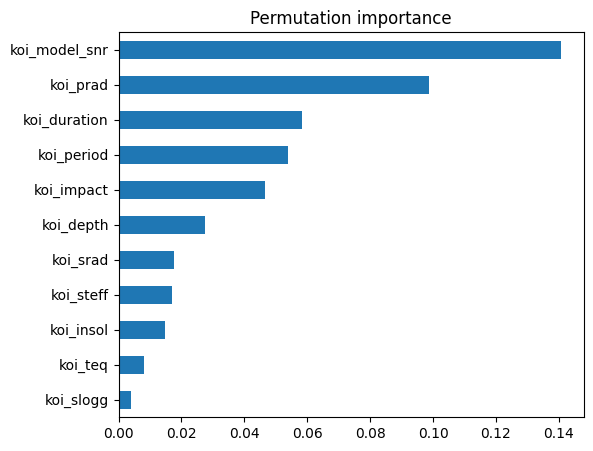

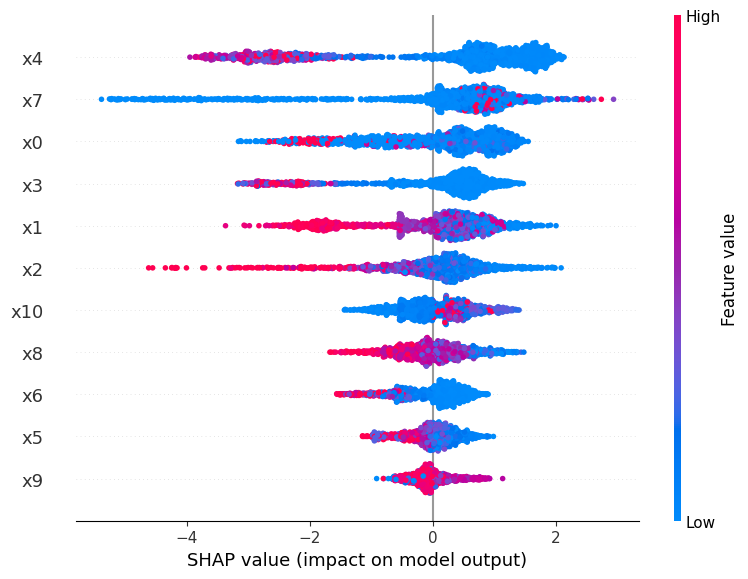

In [14]:
# 8. Explainability: permutation importance (any model) + SHAP (tree models)
from sklearn.inspection import permutation_importance

pi = permutation_importance(best, X_test[cols], y_test, scoring="average_precision",
                            n_repeats=10, random_state=42, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=cols).sort_values(ascending=False)
print("Top permutation importances (drop in PR-AUC):")
print(imp.head(15).round(4).to_string())
imp.head(15)[::-1].plot.barh(figsize=(6, 5), title="Permutation importance")
plt.show()

if best_name in ("RandomForest", "XGBoost", "LightGBM"):
    import shap
    pre = Pipeline(best.steps[:-1])
    pre.set_output(transform="pandas")
    Xt = pre.transform(X_test[cols])
    sv = shap.TreeExplainer(best.named_steps["clf"]).shap_values(Xt)
    if isinstance(sv, list):
        sv = sv[1]
    elif getattr(sv, "ndim", 2) == 3:
        sv = sv[:, :, 1]
    shap.summary_plot(sv, Xt, max_display=15)
else:
    print("SHAP TreeExplainer skipped (best model is not tree-based).")

In [15]:
# 9. Save a deployable pipeline (imputer + scaler + model, accepts raw rows with NaN)
import joblib, sklearn

joblib.dump({"pipeline": best, "features": cols, "model_name": best_name,
             "sklearn_version": sklearn.__version__}, "kepler_exoplanet_pipeline_v2.joblib")

# sanity check: raw rows (with NaN) go straight in
loaded = joblib.load("kepler_exoplanet_pipeline_v2.joblib")
print("Raw-input prediction works:", loaded["pipeline"].predict(X_test[cols].head(3)))

try:
    from google.colab import files
    files.download("kepler_exoplanet_pipeline_v2.joblib")
except ImportError:
    pass

Raw-input prediction works: [0 1 0]


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
# 10. Rank the CANDIDATE rows (never used in training) by predicted probability of being a real planet
cand = df[df["koi_disposition"] == "CANDIDATE"]
out = cand[[c for c in ["kepid", "kepoi_name"] if c in cand.columns]].copy()
out["p_planet"] = best.predict_proba(cand[cols])[:, 1]
out = out.sort_values("p_planet", ascending=False).reset_index(drop=True)
out.to_csv("candidate_ranking.csv", index=False)
print(len(out), "candidates ranked. Top 10:")
print(out.head(10).to_string())

2248 candidates ranked. Top 10:
      kepid kepoi_name  p_planet
0   5770074  K01928.01  0.998824
1   2444412  K00103.01  0.998715
2   8480285  K00691.01  0.998476
3   7364176  K00373.01  0.997958
4   7749773  K02848.01  0.997917
5   3648437  K01861.01  0.997763
6   8410415  K02291.01  0.997684
7  10386922  K00289.01  0.997653
8   8804283  K01276.01  0.997426
9  10656508  K00211.01  0.997191


In [19]:
# 11. Validate top CANDIDATE predictions against the LIVE NASA Exoplanet Archive
#
# Our dataset is a 2017 Kaggle snapshot of the Kepler cumulative KOI table.
# Some CANDIDATE rows have since been reclassified as CONFIRMED or FALSE
# POSITIVE by NASA. This checks how well our model's rankings match what
# actually happened, using the Exoplanet Archive's TAP API (no key needed).

import pandas as pd
import requests
import time

TAP_URL = "https://exoplanetarchive.ipac.caltech.edu/TAP/sync"

def fetch_current_dispositions(retries=3, timeout=60):
    """Pull the CURRENT koi_disposition for every KOI from the live archive."""
    query = "select kepoi_name,koi_disposition from cumulative"
    params = {"query": query, "format": "csv"}
    for attempt in range(retries):
        try:
            r = requests.get(TAP_URL, params=params, timeout=timeout)
            r.raise_for_status()
            from io import StringIO
            return pd.read_csv(StringIO(r.text))
        except Exception as e:
            print(f"Attempt {attempt+1} failed: {e}")
            time.sleep(3)
    raise RuntimeError("Could not reach the NASA Exoplanet Archive TAP API.")

live = fetch_current_dispositions()
live = live.rename(columns={"koi_disposition": "koi_disposition_now"})
print(f"Fetched current dispositions for {len(live)} KOIs.")

# `out` comes from cell 10 (candidate_ranking.csv): kepid, kepoi_name, p_planet
validated = out.merge(live, on="kepoi_name", how="left")
validated["status_changed"] = validated["koi_disposition_now"] != "CANDIDATE"

print(f"\n{validated['status_changed'].sum()} of {len(validated)} CANDIDATEs "
      f"have since been resolved by NASA.")
print(validated["koi_disposition_now"].value_counts(dropna=False))

# How good were our top-ranked predictions at the time they were made?
resolved = validated[validated["status_changed"]].copy()
if len(resolved):
    resolved["actually_planet"] = (resolved["koi_disposition_now"] == "CONFIRMED").astype(int)
    for k in (20, 50, 100):
        top_k = resolved.sort_values("p_planet", ascending=False).head(k)
        if len(top_k):
            hit_rate = top_k["actually_planet"].mean()
            print(f"Top-{k} by our score, now resolved: "
                  f"{hit_rate:.1%} turned out to be CONFIRMED planets "
                  f"(n={len(top_k)})")

    from sklearn.metrics import roc_auc_score, average_precision_score
    if resolved["actually_planet"].nunique() > 1:
        auc = roc_auc_score(resolved["actually_planet"], resolved["p_planet"])
        ap = average_precision_score(resolved["actually_planet"], resolved["p_planet"])
        print(f"\nOn now-resolved candidates: ROC-AUC = {auc:.3f}, PR-AUC = {ap:.3f}")
else:
    print("No candidates have been resolved yet in the live archive for this sample.")

validated.to_csv("candidate_validation.csv", index=False)
print("\nSaved candidate_validation.csv")

try:
    from google.colab import files
    files.download("candidate_validation.csv")
except ImportError:
    pass

Attempt 1 failed: 400 Client Error: Bad Request for url: https://exoplanetarchive.ipac.caltech.edu/TAP/sync?query=select+kepoi_name%2Ckoi_disposition+from+cumulative&format=csv
Attempt 2 failed: 400 Client Error: Bad Request for url: https://exoplanetarchive.ipac.caltech.edu/TAP/sync?query=select+kepoi_name%2Ckoi_disposition+from+cumulative&format=csv
Attempt 3 failed: 400 Client Error: Bad Request for url: https://exoplanetarchive.ipac.caltech.edu/TAP/sync?query=select+kepoi_name%2Ckoi_disposition+from+cumulative&format=csv


RuntimeError: Could not reach the NASA Exoplanet Archive TAP API.

In [20]:
   import sys, sklearn, numpy, pandas, joblib, xgboost, lightgbm
   print(sys.version)
   for m in (sklearn, numpy, pandas, joblib, xgboost, lightgbm): print(m.__name__, m.__version__)
   print(best_name, len(cols))

3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
sklearn 1.6.1
numpy 2.1.3
pandas 2.2.3
joblib 1.6.0
xgboost 3.4.1
lightgbm 4.6.0
LightGBM 11


**Next steps for the paper**
- Compare `candidate_ranking.csv` with the *current* NASA Exoplanet Archive dispositions. Candidates that were later confirmed or rejected are a free, temporal validation set.
- Report the ablation table, CV mean ± std, bootstrap CIs, and the paper-style MLP on the same split.
- Mention the limits: single Kaggle snapshot, KOI catalog only (no light curves).